### Deep Agents overview:

Build agents that can plan, use sub agents, and leverage file systems for complex tasks

- deep aganets is a standalone library for building agents that can tackle complex, multistep tasks..

- build on lang graph:
    -applications like Claude code, Deep research, Manus..

- deep agents comes with planning capabilities, file systems for context management, and the ability to spawn sub agents.


### When to use deep agents:
Use deep agents when you need agents that can:
1. handle complex, multi step tasks that require planning and decomposition.
2. Manage large amounts of context through file system tools
3. Delegate wokr to sub agents for context isolation
4. persist memory across conversations and threads/

In [ ]:
### bASIC dEEP AGENT
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"]= os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]= os.getenv("TAVILY_API_KEY")

In [ ]:
# Tools for th einternet search**

# load tavily client:
from tavily import TavilyClient
from typing import Literal

tavily_client=TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))

#use this client in a tool** internet web search tool
def web_search(query: str, 
               max_results: int=5, 
               topic: Literal["sports", "news","finance"]="general", 
               include_raw_content: bool =False):
    """ 
    Run a web search
    """
    return tavily_client.search(query,max_results= max_results, include_raw_content=include_raw_content, topic=topic)
        

In [5]:
# create models

from langchain.chat_models import init_chat_model

model= init_chat_model("groq:openai/gpt-oss-20b")
model

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.4', 'langchain': '1.4.8'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000288936B97F0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000288936BA270>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

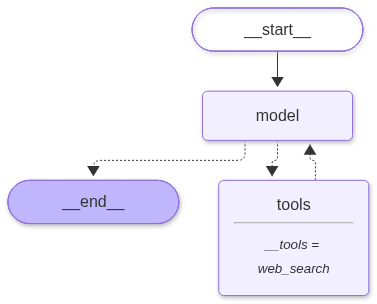

In [10]:
## Basic agent:::

from langchain.agents import create_agent

simple_agent=create_agent(
    model=model, 
    tools=[web_search]
)

simple_agent

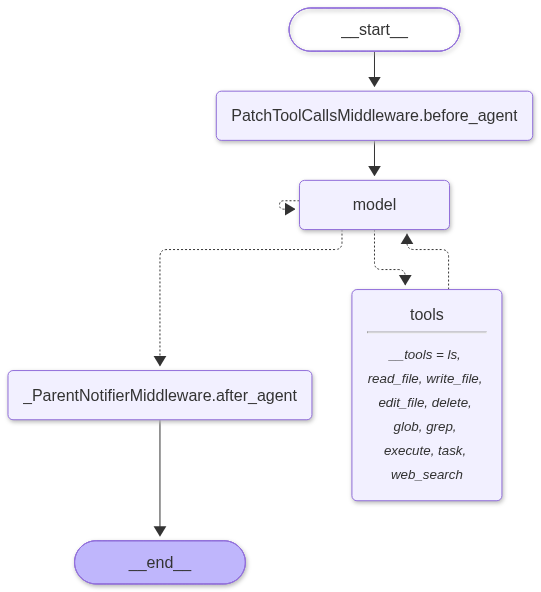

In [ ]:
# create deep agent

# 1. Define Prompt

# 2. Define agent
# from langchain.agents import create_aagent this is for noraml agent

from deepagents import create_deep_agent # for deep agents


deep_agent=create_deep_agent(
    model=model,
    tools=[web_search],
    system_prompt="Act as a researcher"
)

deep_agent  # they will have some middleware attached..





In [13]:
## execute deep agent

result = deep_agent.invoke({
    "messages":[{
        "role":"user",
        "content":"What is langchain"
    }]
})

result
'''
Here deep agent internally follow the entire workflow..

middleware-> we have hooks **

when ever a task is assigned, a sub agent is assigned and the task is tracked

conversation will be summarized automatically..

hook is used, as an when needed, based on how to resolve it..

'''

'\nHere deep agent internally follow the entire workflow..\n\nmiddleware-> we have hooks **\n\nwhen ever a task is assigned, a sub agent is assigned and the task is tracked\n\nconversation will be summarized automatically..\n\nhook is used, as an when needed, based on how to resolve it..\n\n'

In [14]:
result['messages']

[HumanMessage(content='What is langchain', additional_kwargs={}, response_metadata={}, id='39151e70-da41-4331-8d6d-b5e3587b3c55'),
 AIMessage(content='**LangChain** is an open‑source framework (started by Harrison Chase in 2021) that makes it easier to build applications powered by large language models (LLMs).  \nIts core idea is to treat an LLM as a *function* that can be composed, chained, and augmented with other tools.  \n\nKey features:\n\n| Feature | What it does |\n|---------|--------------|\n| **Prompt templates** | Reusable prompt “blueprints” that can be filled with dynamic data. |\n| **Chains** | Sequences of calls (e.g., LLM → parser → LLM) that transform input to output. |\n| **Agents** | Auto‑select and call the best tool (e.g., LLM, API, database) for a given question. |\n| **Memory** | Store conversational context, external knowledge, or state across turns. |\n| **Tool integration** | Wrap APIs, SQL databases, web search, etc., so the LLM can “call” them. |\n| **Callba

In [15]:
result['messages'][-1]

AIMessage(content='**LangChain** is an open‑source framework (started by Harrison Chase in 2021) that makes it easier to build applications powered by large language models (LLMs).  \nIts core idea is to treat an LLM as a *function* that can be composed, chained, and augmented with other tools.  \n\nKey features:\n\n| Feature | What it does |\n|---------|--------------|\n| **Prompt templates** | Reusable prompt “blueprints” that can be filled with dynamic data. |\n| **Chains** | Sequences of calls (e.g., LLM → parser → LLM) that transform input to output. |\n| **Agents** | Auto‑select and call the best tool (e.g., LLM, API, database) for a given question. |\n| **Memory** | Store conversational context, external knowledge, or state across turns. |\n| **Tool integration** | Wrap APIs, SQL databases, web search, etc., so the LLM can “call” them. |\n| **Callbacks & logging** | Hook into events for debugging, monitoring, or custom analytics. |\n| **Extensibility** | Add custom LLMs, embeddi

In [16]:
result['messages'][-1].content

'**LangChain** is an open‑source framework (started by Harrison Chase in 2021) that makes it easier to build applications powered by large language models (LLMs).  \nIts core idea is to treat an LLM as a *function* that can be composed, chained, and augmented with other tools.  \n\nKey features:\n\n| Feature | What it does |\n|---------|--------------|\n| **Prompt templates** | Reusable prompt “blueprints” that can be filled with dynamic data. |\n| **Chains** | Sequences of calls (e.g., LLM → parser → LLM) that transform input to output. |\n| **Agents** | Auto‑select and call the best tool (e.g., LLM, API, database) for a given question. |\n| **Memory** | Store conversational context, external knowledge, or state across turns. |\n| **Tool integration** | Wrap APIs, SQL databases, web search, etc., so the LLM can “call” them. |\n| **Callbacks & logging** | Hook into events for debugging, monitoring, or custom analytics. |\n| **Extensibility** | Add custom LLMs, embeddings, vector stores

In [17]:
result['files']

{}